# 조건부 엣지

**이 노트북에서 할 일**

1. 02절 상태 형식에 점수 칸과 답 칸을 더하고 노드를 넷으로 늘립니다.
2. 점수 칸을 읽어 이름표를 내놓는 조건 함수를 만들어 그래프 없이 먼저 불러 봅니다.
3. 조건부 엣지로 갈래를 적고 점수 하나만 바꿔 두 경로를 실행합니다.
4. 기준값과 같은 점수를 넣어 보고 조건부 엣지를 뺀 그래프와도 견줍니다.

**준비물** — 이 절은 OpenAI API 키를 쓰지 않습니다.
모델 요청이 0번이라 드는 비용이 없습니다.
읽어 오는 자료 파일도 없고 새로 쓰는 파일도 없습니다.
실행 시간은 1분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangGraph 1.2.11을 설치합니다.
실습 폴더 잠금 파일은 LangChain 1.4.0도 함께 고정하지만 이 절은 부르지 않습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 4~8절을 읽습니다.
조건 함수를 만들어 조건부 엣지로 붙이고 점수 하나만 바꿔 두 번 실행하는 자리입니다.
9절과 10절은 값을 하나씩 바꿔 보는 자리입니다.
11절은 네 실행을 기록 한 줄씩으로 만들어 표로 견주는 자리입니다.
준비부터 끝까지 함께 실행하고 실습 시간에 다시 읽습니다.

실습 폴더 `labs/part4/ch13-langgraph-basics`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

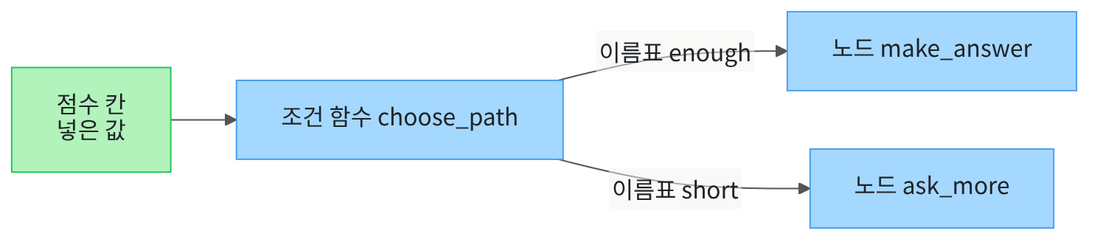

맨 왼쪽 초록 상자가 그래프에 넣은 점수 칸입니다.
가운데 파란 상자가 그 값을 읽는 조건 함수입니다.
거기서 화살표 두 개가 갈라지고 화살표마다 이름표가 하나씩 적혀 있습니다.
이름표가 오른쪽 두 노드 가운데 하나를 가리킵니다.

## 1. 준비

첫 셀은 패키지 하나를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11"
from importlib.metadata import version

print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11


**결과 읽기** — 설치가 끝나면 `langgraph: 1.2.11`이 보입니다.
이 노트북의 출력은 2026-09-19에 이 판으로 실행한 결과입니다.

다음 셀은 이름 여섯 개를 불러옵니다.
02절에서 불러온 것과 같은 여섯 개입니다.
이 절에서 새로 쓰는 것은 불러오는 이름이 아니라 설계 객체의 메서드 하나입니다.

In [2]:
# 02절에서 쓴 이름 여섯 개를 그대로 불러옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

print("불러온 이름:", "operator", "Annotated", "TypedDict", "StateGraph", "START", "END")

불러온 이름: operator Annotated TypedDict StateGraph START END


**결과 읽기** — 출력 줄은 `불러온 이름: operator Annotated TypedDict StateGraph START END` 하나입니다.
02절과 같은 줄입니다.
이 절이 새로 쓰는 메서드 `add_conditional_edges`는 설계 객체에 이미 들어 있어 따로 불러오지 않습니다.

## 2. 이 절에서 쓸 값 정하기

01절과 02절에서 쓴 첫 질문을 글자까지 같게 씁니다.
길을 가르는 데 쓸 점수 두 개와 기준값 하나를 함께 정합니다.

In [3]:
# 01절 질문과 이 절에서 넣어 볼 점수 두 개와 길을 가르는 기준값을 정합니다
first_question = "  대출 기간은 며칠인가요?  "
high_score = 0.82
low_score = 0.41
enough_score = 0.7
print("첫 질문:", first_question)
print("첫 질문의 글자 수:", len(first_question))
print("높은 점수:", high_score)
print("낮은 점수:", low_score)
print("길을 가르는 기준값:", enough_score)

첫 질문:   대출 기간은 며칠인가요?  
첫 질문의 글자 수: 17
높은 점수: 0.82
낮은 점수: 0.41
길을 가르는 기준값: 0.7


**결과 읽기** — 출력 줄 `첫 질문의 글자 수: 17`은 01절·02절과 같은 값입니다.
출력 줄 `높은 점수: 0.82`와 `낮은 점수: 0.41`이 이 절에서 견줄 두 값입니다.
출력 줄 `길을 가르는 기준값: 0.7`이 두 값을 가르는 자리입니다.
세 값은 모두 사람이 정한 예이고 무엇을 재서 얻은 값이 아닙니다.

## 3. 상태 형식 넓히기

02절 상태 형식에는 칸이 셋 있었고 실행 흔적 칸에만 이어 붙이기 규칙을 적었습니다.
이 절은 그 셋에 점수 칸과 답 칸을 더해 다섯으로 넓힙니다.
칸 `score`에는 길을 가를 값을 미리 넣어 두고 칸 `answer`에는 고른 노드가 값을 적습니다.

In [4]:
# 02절 상태 형식에 점수 칸과 답 칸을 더한 상태 형식을 만듭니다
class RouteState(TypedDict):
    question: str
    query: str
    score: float
    answer: str
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `score`의 값 갈래 `float`는 소수점이 있는 수를 뜻합니다.
칸 `trace`의 규칙은 02절에서 적은 것과 글자까지 같습니다.
새로 더한 칸 두 개에는 규칙을 적지 않아 마지막 갱신이 값을 바꿉니다.

다음 셀은 01절·02절에서 쓴 출력 함수에 줄 두 개를 더한 판입니다.

In [5]:
# 상태의 칸 다섯 개를 라벨 줄 아래에 한 줄씩 출력합니다
def print_state(label, state):
    print(label)
    print("질문 칸 |", state["question"])
    print("검색어 칸 |", state["query"])
    print("점수 칸 |", state["score"])
    print("답 칸 |", state["answer"])
    print("실행 흔적 칸 |", state["trace"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
라벨 줄을 따로 출력하고 그 아래에 칸을 한 줄씩 적습니다.
02절 판과 견주면 `점수 칸 |`과 `답 칸 |` 두 줄이 늘었습니다.

다음 셀은 점수 칸만 다른 처음 상태를 만들어 내는 함수입니다.
이 절은 같은 그래프에 처음 상태를 네 번 넣으므로 만드는 자리를 한곳에 모읍니다.

In [6]:
# 점수 칸만 다른 처음 상태를 만들어 냅니다
def new_state(score):
    state = {}
    state["question"] = first_question
    state["query"] = ""
    state["score"] = score
    state["answer"] = ""
    state["trace"] = []
    return state

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `new_state`는 앞 셀에서 정한 이름 `first_question`을 그대로 읽습니다.
받는 값은 점수 하나뿐이고 나머지 칸 넷은 언제나 같게 채웁니다.

## 4. 노드 네 개

앞의 두 노드는 02절과 글자까지 같습니다.
뒤의 두 노드가 이 절에서 새로 만드는 갈래 끝 노드입니다.
네 노드 모두 실행 흔적 칸에는 자기 이름 하나만 담아 냅니다.

In [7]:
# 질문 칸의 앞뒤 빈칸을 없애고 실행 흔적에는 자기 이름만 담아 냅니다
def normalize(state):
    clean_question = state["question"].strip()
    return {"question": clean_question, "trace": ["normalize"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `strip()`은 글 앞뒤의 빈칸을 없앱니다.

다음 셀은 검색어 칸을 만드는 노드입니다.

In [8]:
# 물음표와 맺음말을 지워 검색어를 만들고 실행 흔적에는 자기 이름만 담아 냅니다
def make_query(state):
    without_mark = state["question"].replace("?", "")
    plain = without_mark.replace("인가요", "")
    return {"query": plain.strip(), "trace": ["make_query"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `replace()`는 글에서 찾은 말을 다른 말로 바꿉니다.
여기서는 물음표와 맺음말 `인가요`를 빈 글로 바꿔 지웁니다.

다음 셀은 점수가 넉넉할 때 지날 노드입니다.

In [9]:
# 점수가 기준값 위일 때 지날 노드로 답 칸과 자기 이름을 담아 냅니다
def make_answer(state):
    return {"answer": "찾은 자료로 답을 만듭니다", "trace": ["make_answer"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드는 답 칸에 적을 글 하나와 자기 이름을 담아 냅니다.
실제로 자료를 찾거나 모델을 부르지는 않습니다.

다음 셀은 점수가 모자랄 때 지날 노드입니다.

In [10]:
# 점수가 기준값 아래일 때 지날 노드로 답 칸과 자기 이름을 담아 냅니다
def ask_more(state):
    return {"answer": "자료를 더 찾아야 합니다", "trace": ["ask_more"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
앞 노드와 모양은 같고 답 칸에 적는 글과 자기 이름만 다릅니다.

## 5. 조건 함수 — 이름표를 내놓기

조건 함수는 상태를 받아 다음에 지날 길의 이름표를 내놓는 함수입니다.
갈림길 앞에서 표지판을 보고 왼쪽인지 오른쪽인지 말하는 사람과 같습니다.
이 함수는 칸을 하나도 고치지 않고 이름표 한 개만 내놓습니다.
노드가 딕셔너리를 내놓는 것과 내놓는 모양부터 다릅니다.

In [11]:
# 점수 칸을 읽어 다음에 지날 길의 이름표를 내놓습니다
def choose_path(state):
    if state["score"] >= enough_score:
        return "enough"
    return "short"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `choose_path`는 앞 셀에서 정한 이름 `enough_score`를 그대로 읽습니다.
비교 `>=`는 기준값과 같은 값도 넉넉한 쪽으로 봅니다.
내놓는 값 `enough`와 `short`는 노드 이름이 아니라 우리가 지은 이름표입니다.

다음 셀은 그래프 없이 이 함수만 직접 불러 봅니다.
점수 칸만 든 작은 딕셔너리를 넣어도 이 함수는 점수 칸만 읽습니다.

In [12]:
# 그래프 없이 조건 함수만 직접 불러 두 점수의 이름표를 봅니다
high_only = {"score": high_score}
low_only = {"score": low_score}
print("높은 점수의 이름표:", choose_path(high_only))
print("낮은 점수의 이름표:", choose_path(low_only))

높은 점수의 이름표: enough
낮은 점수의 이름표: short


**결과 읽기** — 출력 줄 `높은 점수의 이름표: enough`와 `낮은 점수의 이름표: short`가 보입니다.
점수 하나가 이름표 하나로 바뀌었습니다.
이 함수는 노드를 실행하지 않고 어느 길로 갈지만 말합니다.

## 6. 조립 — 조건부 엣지 붙이기

먼저 설계 객체를 만들고 노드 네 개를 등록합니다.
01절·02절에서는 노드가 둘이었습니다.

In [13]:
# 설계 객체를 만들고 노드 네 개를 등록합니다
builder = StateGraph(RouteState)
builder.add_node("normalize", normalize)
builder.add_node("make_query", make_query)
builder.add_node("make_answer", make_answer)
builder.add_node("ask_more", ask_more)
print("등록한 노드 수:", len(builder.nodes))

등록한 노드 수: 4


**결과 읽기** — 출력 줄 `등록한 노드 수: 4`가 보입니다.
갈래 끝 노드 두 개가 늘어 01절·02절의 두 배입니다.

다음 셀은 이름표를 실제 노드 이름에 잇는 표를 만듭니다.
이 표를 이름표 표(`path_map`)라고 부릅니다.

In [14]:
# 조건 함수가 내놓는 이름표를 실제 노드 이름에 잇는 표를 만듭니다
path_map = {"enough": "make_answer", "short": "ask_more"}
print("이름표와 노드 이름을 이은 표:")
for label in path_map:
    print(label, "->", path_map[label])

이름표와 노드 이름을 이은 표:
enough -> make_answer
short -> ask_more


**결과 읽기** — 라벨 줄 `이름표와 노드 이름을 이은 표:` 아래 두 줄이 나옵니다.
줄 `enough -> make_answer`와 줄 `short -> ask_more`입니다.
왼쪽이 조건 함수가 내놓는 이름표이고 오른쪽이 실제 노드 이름입니다.

다음 셀은 엣지를 적고 컴파일합니다.
메서드 `add_conditional_edges(앞 노드, 조건 함수, 이름표 표)`는 앞 노드가 끝난 뒤 조건 함수를 부릅니다.
그 함수가 내놓은 이름표를 이름표 표에서 찾아 실제 노드로 잇습니다.

In [15]:
# 고정 엣지 네 개와 조건부 엣지 한 개를 적고 컴파일합니다
builder.add_edge(START, "normalize")
builder.add_edge("normalize", "make_query")
builder.add_conditional_edges("make_query", choose_path, path_map)
builder.add_edge("make_answer", END)
builder.add_edge("ask_more", END)
graph = builder.compile()
print("고정 엣지로 적은 수:", len(builder.edges))
print("컴파일 결과의 종류:", type(graph))

고정 엣지로 적은 수: 4
컴파일 결과의 종류: <class 'langgraph.graph.state.CompiledStateGraph'>


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 4`가 보입니다.
조건부 엣지는 이 수에 들어 있지 않고 따로 적힙니다.
출력 줄의 종류 이름 `CompiledStateGraph`는 01절·02절과 같습니다.

다음 셀은 컴파일한 그래프가 스스로 그린 구조 문자열을 받아 옵니다.
01절에서 한 번 본 출력입니다.

In [16]:
# 컴파일한 그래프가 스스로 그린 구조 문자열을 받아 옵니다
structure_text = graph.get_graph().draw_mermaid()
print("그래프가 그린 구조:")
print(structure_text)

그래프가 그린 구조:
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	normalize(normalize)
	make_query(make_query)
	make_answer(make_answer)
	ask_more(ask_more)
	__end__([<p>__end__</p>]):::last
	__start__ --> normalize;
	make_query -. &nbsp;short&nbsp; .-> ask_more;
	make_query -. &nbsp;enough&nbsp; .-> make_answer;
	normalize --> make_query;
	ask_more --> __end__;
	make_answer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**결과 읽기** — 라벨 줄 `그래프가 그린 구조:` 아래에 여러 줄이 나옵니다.
이름 `make_query`로 시작하는 줄이 두 개입니다.
두 줄 모두 점선 표시 `-.`와 `.->` 사이에 이름표가 적혀 있습니다.
한 줄은 이름표 `enough`로 `make_answer`를 가리킵니다.
다른 줄은 이름표 `short`로 `ask_more`를 가리킵니다.

구조에는 갈래 둘이 모두 적혀 있습니다.
실행 한 번이 어느 쪽으로 갈지는 아직 정해지지 않았습니다.

## 7. 실행 1 — 높은 점수

실행 전에 예상해 봅니다.
점수 `0.82`는 기준값보다 크니 이름표 `enough`를 지나 노드 `make_answer`로 갈 것입니다.

In [17]:
# 점수 칸에 높은 점수를 넣고 그래프를 실행합니다
high_state = new_state(high_score)
high_result = graph.invoke(high_state)
print_state("높은 점수 결과", high_result)

높은 점수 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
점수 칸 | 0.82
답 칸 | 찾은 자료로 답을 만듭니다
실행 흔적 칸 | ['normalize', 'make_query', 'make_answer']


**결과 읽기** — 줄 `실행 흔적 칸 | ['normalize', 'make_query', 'make_answer']`에 이름 셋이 남았습니다.
줄 `답 칸 | 찾은 자료로 답을 만듭니다`가 노드 `make_answer`가 적은 값입니다.
이름 `ask_more`는 실행 흔적 칸에 없습니다.
줄 `검색어 칸 | 대출 기간은 며칠`은 01절·02절과 같은 값입니다.

## 8. 실행 2 — 낮은 점수

바꿀 값은 점수 칸 하나입니다.
그래프와 질문은 실행 1과 그대로 같습니다.
실행 전에 예상해 봅니다. 이름표 `short`를 지나 노드 `ask_more`로 갈 것입니다.

In [18]:
# 점수 칸에 낮은 점수를 넣고 같은 그래프를 실행합니다
low_state = new_state(low_score)
low_result = graph.invoke(low_state)
print_state("낮은 점수 결과", low_result)

낮은 점수 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
점수 칸 | 0.41
답 칸 | 자료를 더 찾아야 합니다
실행 흔적 칸 | ['normalize', 'make_query', 'ask_more']


**결과 읽기** — 줄 `실행 흔적 칸 | ['normalize', 'make_query', 'ask_more']`에 이름 셋이 남았습니다.
셋째 이름만 실행 1과 다릅니다.
줄 `답 칸 | 자료를 더 찾아야 합니다`가 노드 `ask_more`가 적은 값입니다.

다음 셀은 두 실행을 칸별로 견줍니다.

In [19]:
# 두 실행의 결과를 칸별로 견줍니다
print("질문 칸이 같은가:", high_result["question"] == low_result["question"])
print("검색어 칸이 같은가:", high_result["query"] == low_result["query"])
print("답 칸이 같은가:", high_result["answer"] == low_result["answer"])
print("실행 흔적 칸이 같은가:", high_result["trace"] == low_result["trace"])
assert high_result["trace"] == ["normalize", "make_query", "make_answer"]
assert low_result["trace"] == ["normalize", "make_query", "ask_more"]

질문 칸이 같은가: True
검색어 칸이 같은가: True
답 칸이 같은가: False
실행 흔적 칸이 같은가: False


**결과 읽기** — 출력 줄 `질문 칸이 같은가: True`와 `검색어 칸이 같은가: True`가 보입니다.
앞 노드 두 개는 두 실행에서 같은 일을 했습니다.
출력 줄 `답 칸이 같은가: False`와 `실행 흔적 칸이 같은가: False`가 갈린 자리입니다.
점수 칸 하나를 바꾸자 지난 노드와 답 칸이 함께 달라졌습니다.

## 9. 값 바꿔 보기 ① 기준값과 똑같은 점수

바꿀 값은 점수 칸 하나입니다.
기준값과 똑같은 `0.7`을 넣습니다.
조건 함수는 비교 `>=`로 적혀 있습니다.
실행 전에 예상해 봅니다. 같은 값도 넉넉한 쪽으로 보아 노드 `make_answer`로 갈 것입니다.

In [20]:
# 점수 칸에 기준값과 똑같은 값을 넣어 어느 길로 가는지 봅니다
same_state = new_state(enough_score)
same_result = graph.invoke(same_state)
print_state("기준값과 같은 점수 결과", same_result)

기준값과 같은 점수 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
점수 칸 | 0.7
답 칸 | 찾은 자료로 답을 만듭니다
실행 흔적 칸 | ['normalize', 'make_query', 'make_answer']


**결과 읽기** — 줄 `점수 칸 | 0.7`이 기준값과 같은 값입니다.
줄 `실행 흔적 칸 | ['normalize', 'make_query', 'make_answer']`는 실행 1과 같습니다.
비교 `>=`는 기준값과 같은 값을 넉넉한 쪽으로 보냅니다.
비교를 `>`로 적었다면 다른 쪽으로 갔겠지만 이번에 실행하지는 않았습니다.

## 10. 값 바꿔 보기 ② 조건부 엣지를 빼면

바꿀 것은 엣지를 적는 방법 하나입니다.
같은 노드 네 개를 조건 없이 고정 엣지로만 차례로 잇습니다.
실행 전에 예상해 봅니다. 갈래가 없으니 네 노드가 모두 지날 것입니다.

In [21]:
# 같은 노드 네 개를 새 설계 객체에 등록합니다
fixed_builder = StateGraph(RouteState)
fixed_builder.add_node("normalize", normalize)
fixed_builder.add_node("make_query", make_query)
fixed_builder.add_node("make_answer", make_answer)
fixed_builder.add_node("ask_more", ask_more)
print("등록한 노드 수:", len(fixed_builder.nodes))

등록한 노드 수: 4


**결과 읽기** — 출력 줄 `등록한 노드 수: 4`가 앞 그래프와 같습니다.
짝지은 함수도 앞 그래프와 같습니다.

다음 셀은 엣지만 다르게 적어 컴파일합니다.

In [22]:
# 조건부 엣지 없이 고정 엣지 다섯 개로만 이어 컴파일합니다
fixed_builder.add_edge(START, "normalize")
fixed_builder.add_edge("normalize", "make_query")
fixed_builder.add_edge("make_query", "make_answer")
fixed_builder.add_edge("make_answer", "ask_more")
fixed_builder.add_edge("ask_more", END)
fixed_graph = fixed_builder.compile()
print("고정 엣지로 적은 수:", len(fixed_builder.edges))

고정 엣지로 적은 수: 5


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 5`가 보입니다.
앞 그래프보다 고정 엣지가 하나 많습니다.
이 그래프에는 조건부 엣지가 하나도 없습니다.

다음 셀은 실행 2와 같은 낮은 점수를 넣어 실행합니다.

In [23]:
# 같은 낮은 점수를 넣고 고정 엣지 그래프를 실행합니다
fixed_state = new_state(low_score)
fixed_result = fixed_graph.invoke(fixed_state)
print_state("고정 엣지 결과", fixed_result)
print("실행 흔적 칸의 길이:", len(fixed_result["trace"]))

고정 엣지 결과
질문 칸 | 대출 기간은 며칠인가요?
검색어 칸 | 대출 기간은 며칠
점수 칸 | 0.41
답 칸 | 자료를 더 찾아야 합니다
실행 흔적 칸 | ['normalize', 'make_query', 'make_answer', 'ask_more']
실행 흔적 칸의 길이: 4


**결과 읽기** — 줄 `실행 흔적 칸 | ['normalize', 'make_query', 'make_answer', 'ask_more']`가 보입니다.
출력 줄 `실행 흔적 칸의 길이: 4`가 그 수입니다.
갈래 끝 노드 두 개가 모두 지났습니다.
줄 `답 칸 | 자료를 더 찾아야 합니다`는 마지막에 지난 노드가 적은 값입니다.
답 칸에는 규칙을 적지 않아 앞 노드가 적은 값이 덮였습니다.

## 11. 네 실행을 기록 한 줄씩으로

실행 한 번을 기록 한 줄로 만들어 담아 둡니다.
Ch 9~12와 01절·02절에서 쓴 기록 한 줄과 같은 모양입니다.

In [24]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, state):
    row = {"실행": run_name}
    row["점수 칸"] = state["score"]
    row["지난 노드"] = state["trace"]
    row["답 칸"] = state["answer"]
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
02절 판과 견주면 담는 칸이 점수 칸과 지난 노드와 답 칸으로 바뀌었습니다.

다음 셀은 네 실행의 기록을 목록에 담습니다.

In [25]:
# 네 실행의 기록을 목록에 담습니다
run_rows = []
run_rows.append(run_row("높은 점수", high_result))
run_rows.append(run_row("낮은 점수", low_result))
run_rows.append(run_row("기준값과 같은 점수", same_result))
run_rows.append(run_row("고정 엣지", fixed_result))
print("담은 기록 줄 수:", len(run_rows))

담은 기록 줄 수: 4


**결과 읽기** — 출력 줄 `담은 기록 줄 수: 4`가 보입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [26]:
# 실행과 점수 칸과 지난 노드와 답 칸을 라벨 줄 아래에 차례로 출력합니다
print("실행 | 점수 칸 | 지난 노드 | 답 칸")
for row in run_rows:
    print(row["실행"], "|", row["점수 칸"], "|", row["지난 노드"], "|", row["답 칸"])

실행 | 점수 칸 | 지난 노드 | 답 칸
높은 점수 | 0.82 | ['normalize', 'make_query', 'make_answer'] | 찾은 자료로 답을 만듭니다
낮은 점수 | 0.41 | ['normalize', 'make_query', 'ask_more'] | 자료를 더 찾아야 합니다
기준값과 같은 점수 | 0.7 | ['normalize', 'make_query', 'make_answer'] | 찾은 자료로 답을 만듭니다
고정 엣지 | 0.41 | ['normalize', 'make_query', 'make_answer', 'ask_more'] | 자료를 더 찾아야 합니다


**결과 읽기** — 라벨 줄 아래 네 줄이 나옵니다.
위 두 줄은 점수 칸만 다르고 지난 노드의 셋째 이름과 답 칸이 갈렸습니다.
셋째 줄은 점수 칸이 `0.7`인데 지난 노드가 첫 줄과 같습니다.
넷째 줄만 지난 노드가 넷이고 그 줄이 조건부 엣지를 뺀 그래프의 결과입니다.

## 정리

1. 조건 함수가 점수 칸을 읽어 이름표를 내놓고 이름표 표가 그 이름표를 노드 이름에 이었습니다.
2. 점수 칸 하나만 바꾸자 지난 노드와 답 칸이 함께 달라졌습니다.
3. 조건부 엣지를 빼고 고정 엣지로만 이으면 네 노드가 모두 지났습니다.

04절에서는 사람과 모델의 말을 상태에 쌓는 리듀서 `add_messages`를 씁니다.
이 절까지 상태에 담은 값은 글과 수와 이름 목록뿐이었습니다.